In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from model.hopfield_network import HopfieldNetwork
from notebooks.plot_patterns import plot_patterns
from notebooks.helpers import create_number_of_random_images, read_data_train_hebb, \
    classify_recalls, train_hopfield_from_array, load_and_resize_image_dithering

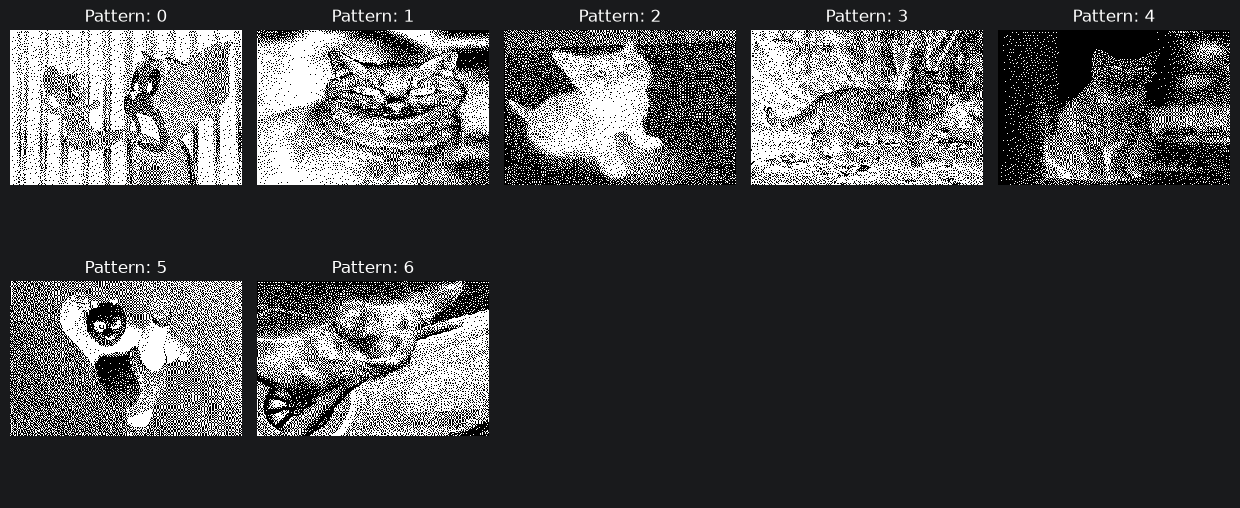

In [2]:
n = 200 * 300
is_async = False
names = [ "tom.png", "cat.png", "cat2.png", "cat3.png", "cat4.png", "panda.png", "sonia.jpg"]
train = np.ndarray((len(names), n))

for i in range(len(names)):
    name = names[i]
    img = load_and_resize_image_dithering(name, (300, 200))
    train[i, :] = img[0, :]

plot_patterns(train, (200, 300))

In [3]:
hn = HopfieldNetwork(n, if_asynchronic=is_async, low_memory=True)
hn.train(train)


'Result: stable. Energy value: -34283.5078125'

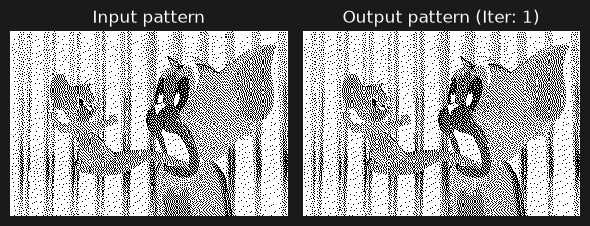

'Result: stable. Energy value: -32330.201171875'

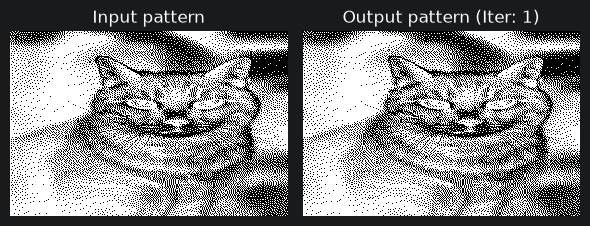

'Result: stable. Energy value: -30638.0390625'

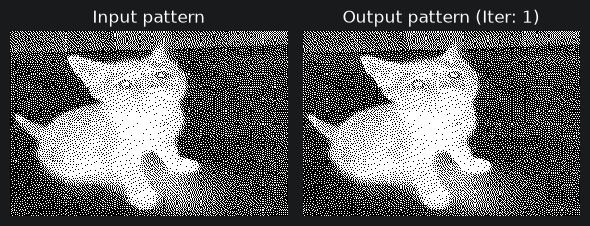

'Result: stable. Energy value: -32139.435546875'

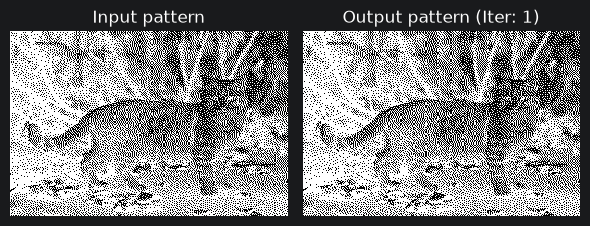

'Result: stable. Energy value: -34490.0625'

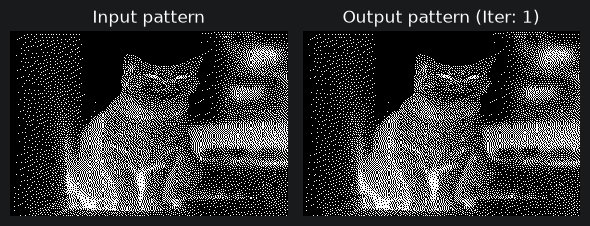

'Result: stable. Energy value: -30159.451171875'

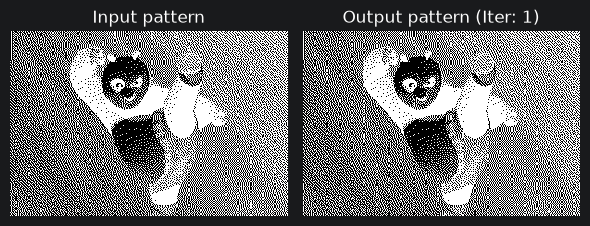

'Result: stable. Energy value: -30083.546875'

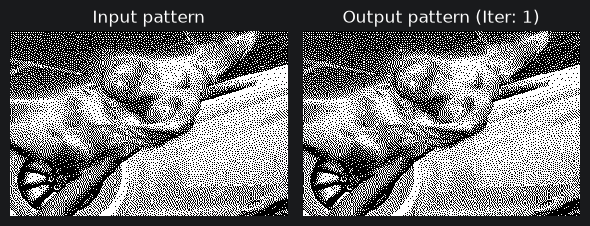

In [4]:
for i in range(train.shape[0]):
    result = hn.recall(train[i], 100)
    display(f"Result: {result["Result"]}. Energy value: {result["Energy"]}")
    hn.plot_first_last(result["History"], (200, 300))

'Result: stable. Energy value: -34283.5078125'

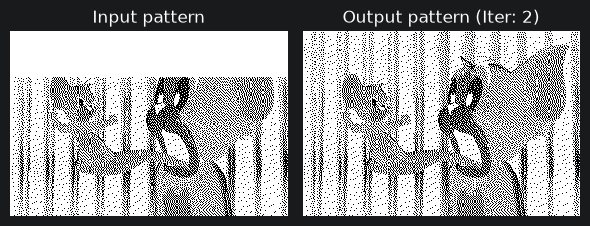

'Result: stable. Energy value: -31373.748046875'

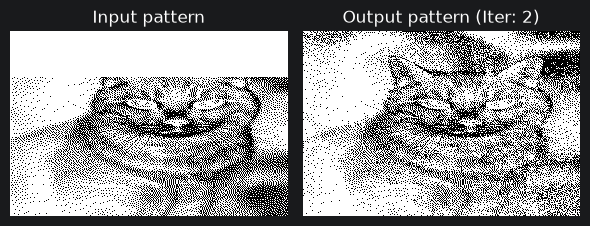

'Result: stable. Energy value: -30638.0390625'

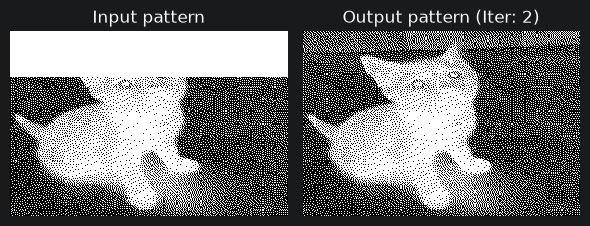

'Result: stable. Energy value: -32139.435546875'

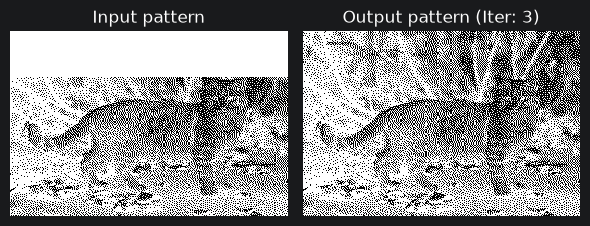

'Result: stable. Energy value: -34490.0625'

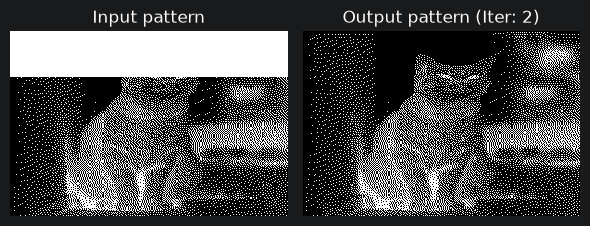

'Result: stable. Energy value: -30159.451171875'

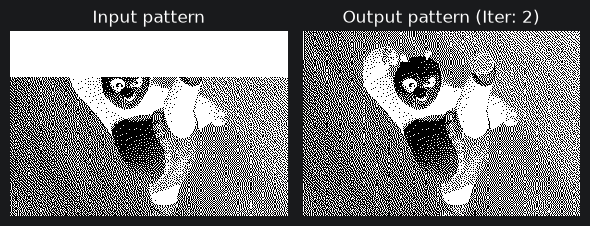

'Result: stable. Energy value: -30083.546875'

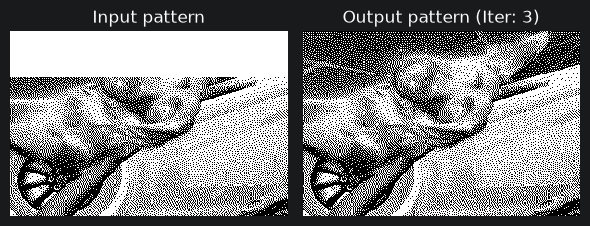

In [5]:
test = np.ndarray((len(names), n))
threshold = int(0.25 * n)
for i in range(len(names)):
    test[i, :] = train[i, :]
    test[i, :threshold] = -1


for i in range(test.shape[0]):
    result = hn.recall(test[i], 100)
    display(f"Result: {result["Result"]}. Energy value: {result["Energy"]}")
    hn.plot_first_last(result["History"], (200, 300))


'Result: stable. Energy value: -34283.5078125'

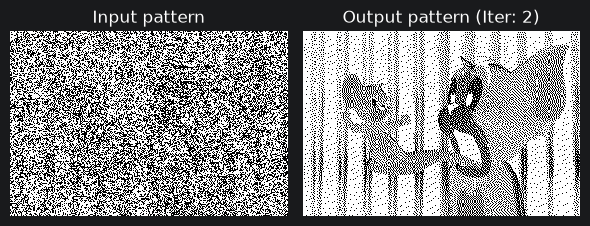

'Result: stable. Energy value: -32330.201171875'

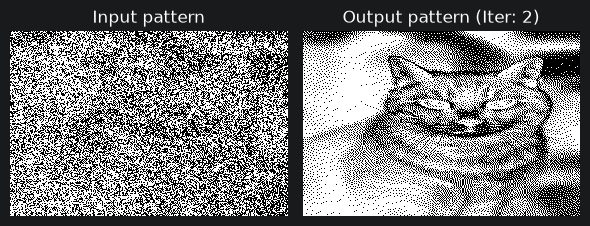

'Result: stable. Energy value: -30638.0390625'

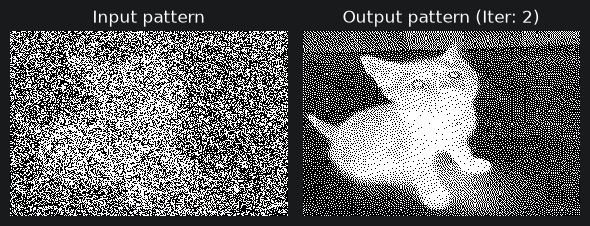

'Result: stable. Energy value: -32139.435546875'

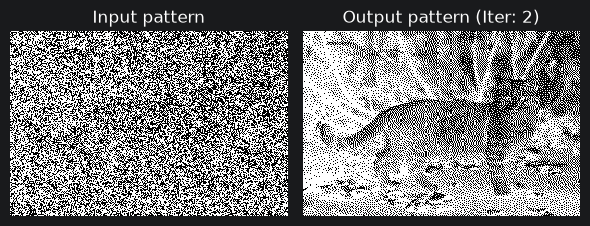

'Result: stable. Energy value: -34490.0625'

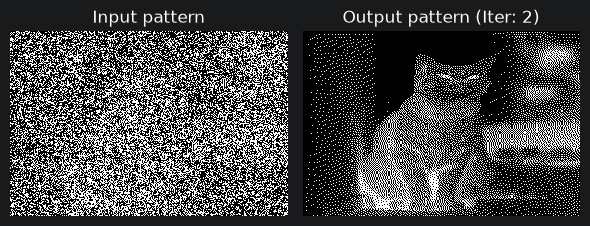

'Result: stable. Energy value: -30159.451171875'

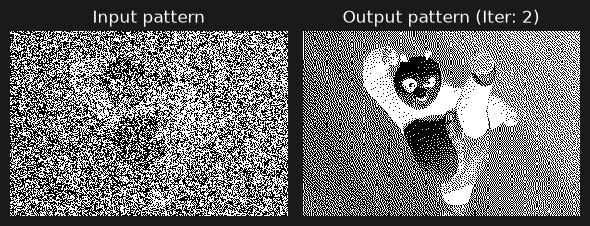

'Result: stable. Energy value: -30083.546875'

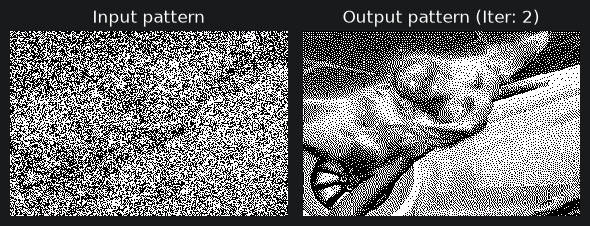

In [6]:
rng = np.random.default_rng(42)
noise_ratio = 0.35
test = train.copy()
noise_mask = rng.random(test.shape) < noise_ratio
test[noise_mask] *= -1

for i in range(test.shape[0]):
    result = hn.recall(test[i], 100)
    display(f"Result: {result['Result']}. Energy value: {result['Energy']}")
    hn.plot_first_last(result["History"], (200, 300))

*Correlation*

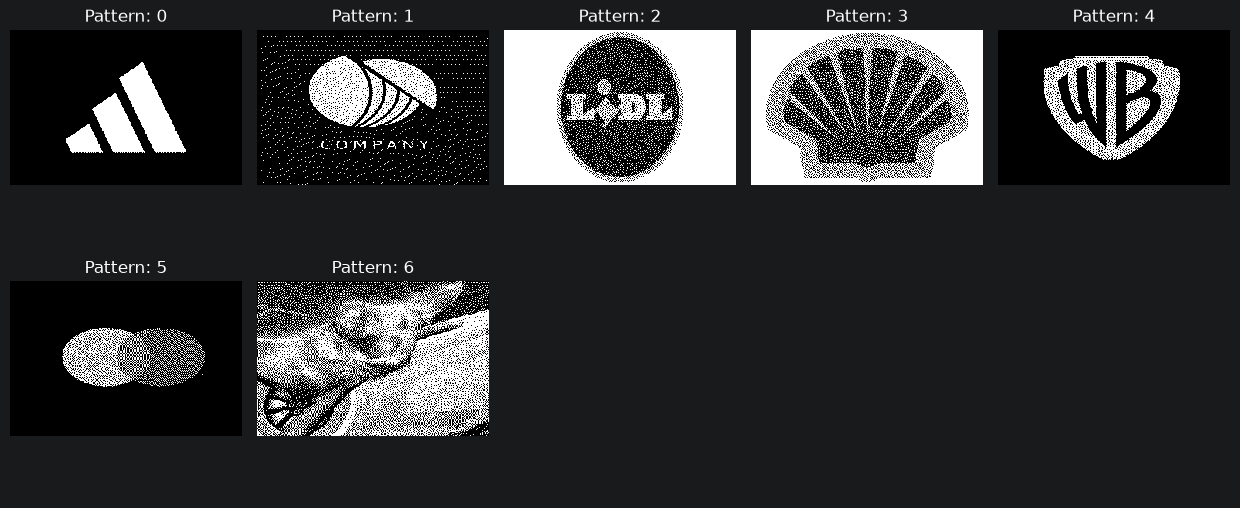

In [7]:
n = 200 * 300
names = [ "img.png", "img_1.png", "img_2.png", "img_3.png", "img_4.png", "img_5.png", "sonia.jpg"]
train = np.ndarray((len(names), n))

for i in range(len(names)):
    name = names[i]
    img = load_and_resize_image_dithering(name, (300, 200))
    train[i, :] = img[0, :]

plot_patterns(train, (200, 300))

'Result: stable. Energy value: -87551.1640625'

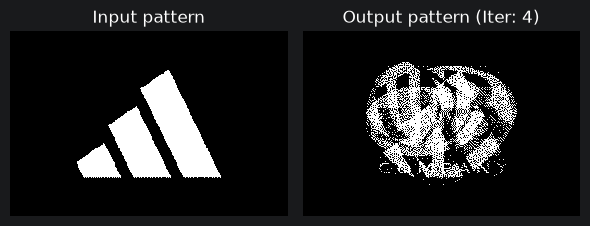

'Result: stable. Energy value: -87551.1640625'

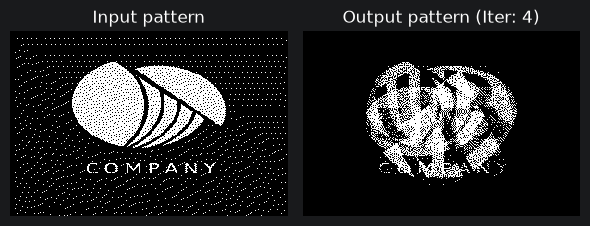

'Result: stable. Energy value: -87551.1640625'

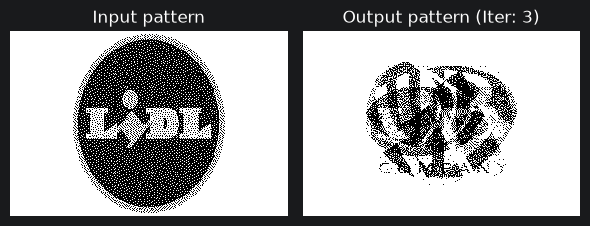

'Result: stable. Energy value: -87551.1640625'

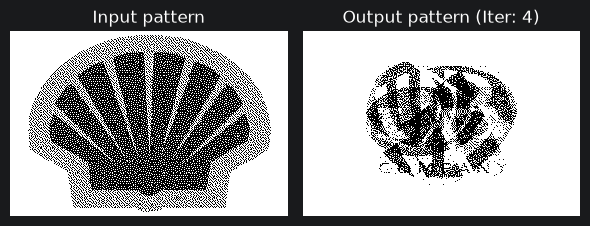

'Result: stable. Energy value: -87551.1640625'

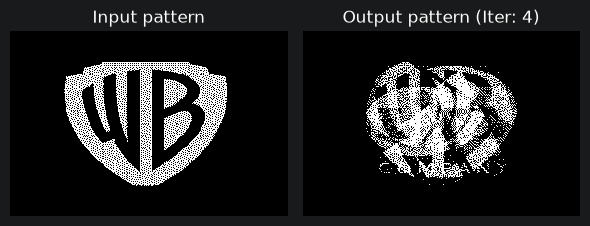

'Result: stable. Energy value: -87551.1640625'

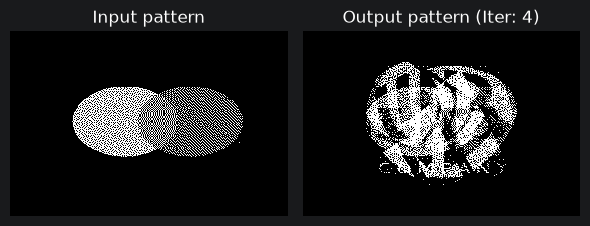

'Result: stable. Energy value: -30378.33984375'

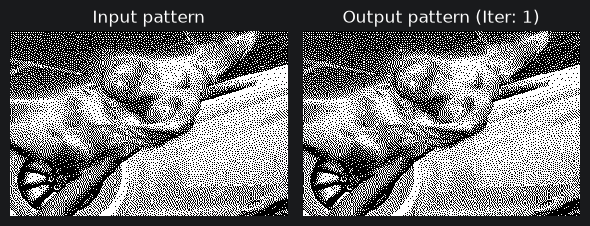

In [8]:
hn = HopfieldNetwork(n, if_asynchronic=is_async, low_memory=True)
hn.train(train)

for i in range(train.shape[0]):
    result = hn.recall(train[i], 100)
    display(f"Result: {result["Result"]}. Energy value: {result["Energy"]}")
    hn.plot_first_last(result["History"], (200, 300))

'Result: stable. Energy value: -87551.1640625'

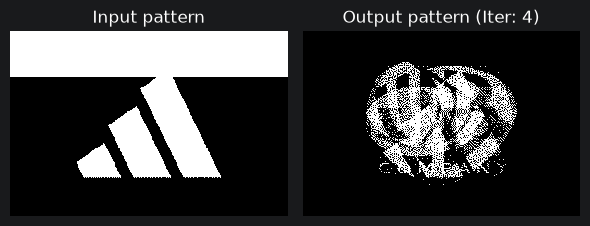

'Result: stable. Energy value: -87551.1640625'

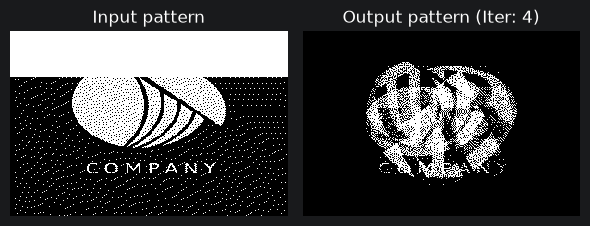

'Result: stable. Energy value: -87551.1640625'

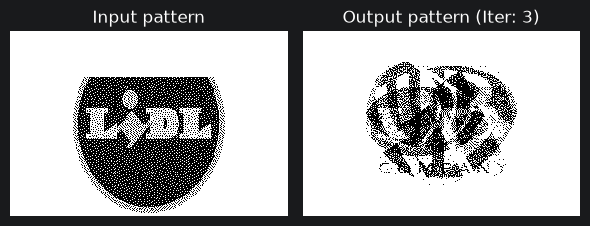

'Result: stable. Energy value: -87551.1640625'

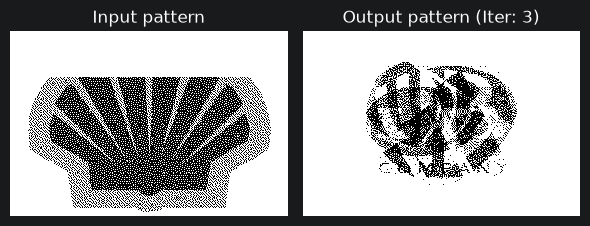

'Result: stable. Energy value: -87551.1640625'

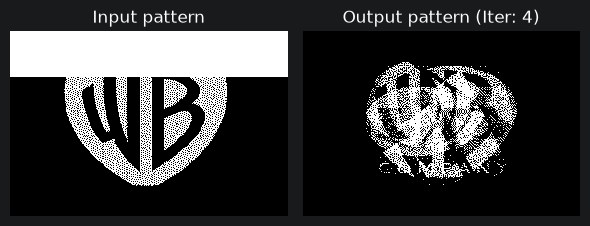

'Result: stable. Energy value: -87551.1640625'

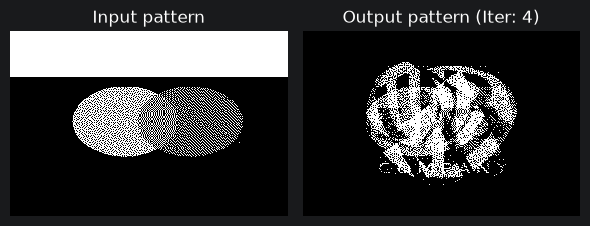

'Result: stable. Energy value: -87551.1640625'

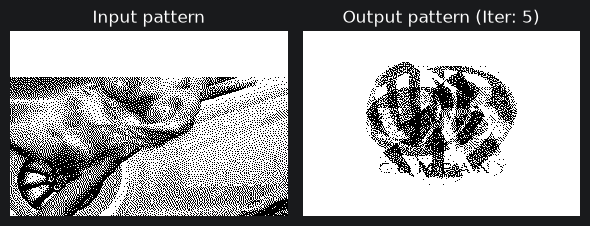

In [9]:

test = np.ndarray((len(names), n))
threshold = int(0.25 * n)
for i in range(len(names)):
    test[i, :] = train[i, :]
    test[i, :threshold] = -1

for i in range(test.shape[0]):
    result = hn.recall(test[i], 100)
    display(f"Result: {result["Result"]}. Energy value: {result["Energy"]}")
    hn.plot_first_last(result["History"], (200, 300))


'Result: stable. Energy value: -87551.1640625'

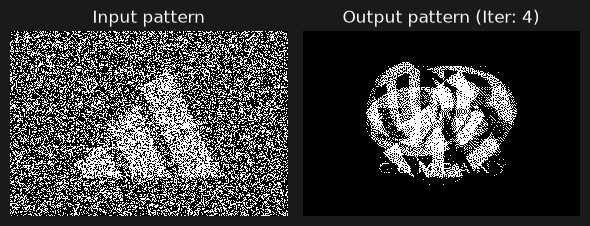

'Result: stable. Energy value: -87551.1640625'

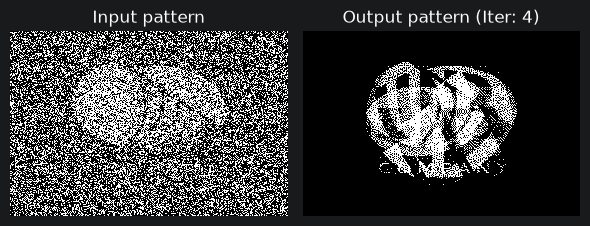

'Result: stable. Energy value: -87551.1640625'

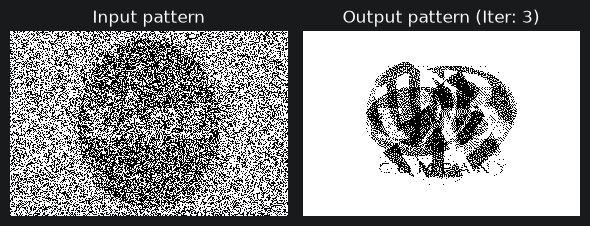

'Result: stable. Energy value: -87551.1640625'

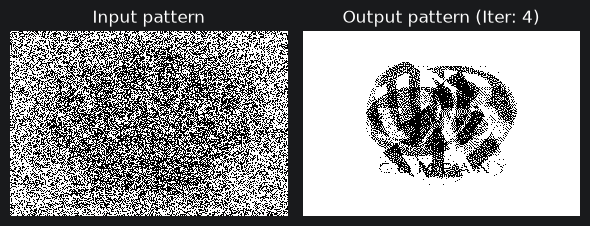

'Result: stable. Energy value: -87551.1640625'

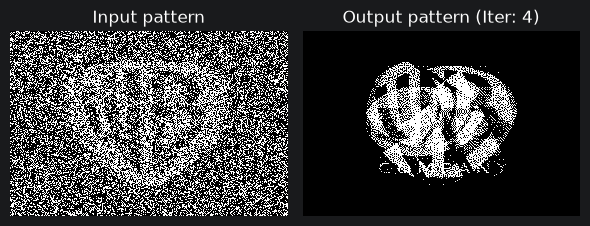

'Result: stable. Energy value: -87551.1640625'

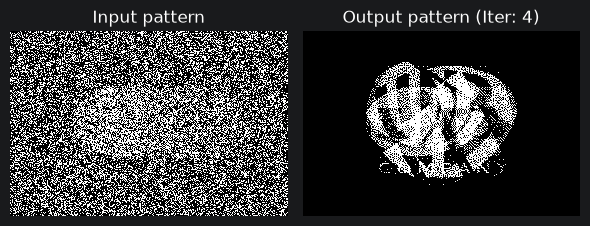

'Result: stable. Energy value: -30378.33984375'

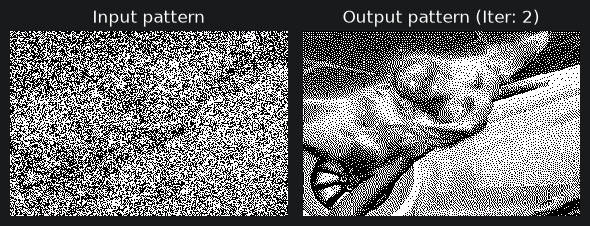

In [10]:
rng = np.random.default_rng(42)
noise_ratio = 0.35
test = train.copy()
noise_mask = rng.random(test.shape) < noise_ratio
test[noise_mask] *= -1

for i in range(test.shape[0]):
    result = hn.recall(test[i], 100)
    display(f"Result: {result['Result']}. Energy value: {result['Energy']}")
    hn.plot_first_last(result["History"], (200, 300))